# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [2]:

# Importar librerías
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [3]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


<div class="alert alert-block alert-success">

Cargaste el dataset con la ruta correcta y llamaste a `df.info()` de inmediato. La salida confirma 15,000 filas, 12 columnas, ningún valor faltante y los tipos de datos, lo que te da una base sólida para el análisis. Una verificación adicional opcional es `df.duplicated().sum()` y `df['id_cliente'].is_unique`, que respaldaría tu suposición posterior sobre la calidad de los datos.

</div>

#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [4]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso` 
- `visitas_mes` 
- `compras_mes` 
- `gasto_publicidad_dirigida` 
- `satisfaccion` 
- `ingreso_anual` 

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está almacenada como tipo de dato **float**, por lo que **requiere una transformación** a tipo **int** para eliminar los decimales y representar la edad en años completos.

**Variables binarias**  
Las siguientes columnas representan variables binarias:

- `miembro_premium`
- `abandono`


Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [5]:
# Corregir el tipo de dato
df["edad"] = df["edad"].astype("Int64")

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  Int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: Int64(1), float64(4), int64(4), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
df[["edad",
"nivel_ingreso",
"visitas_mes",
"compras_mes",
"gasto_publicidad_dirigida",
"satisfaccion",
"ingreso_anual"]].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


**Diagnóstico inicial de variables numéricas**

- `edad` — La distribución está relativamente centrada y comprende edades de 18 a 75 años.
- `nivel_ingreso` — Media y mediana similares (~30,020), sin diferencias importantes en la tendencia central.
- `visitas_mes` — Promedio de 10 visitas, con poca dispersión respecto a la media.
- `compras_mes` — Promedio de 1.2 compras; al menos 25% de los clientes no registran compras.
- `gasto_publicidad_dirigida` — Presenta alta variabilidad, con valores entre 0 y 75.51.
- `satisfaccion` — Promedio de 3.6 sobre 5, lo que refleja una valoración intermedia-alta.
- `ingreso_anual` — Presenta asimetría positiva, ya que la media (36.59) supera la mediana (30.71), posiblemente por valores extremos. Y el percentil 25 de los ingresos anuales es 0, por lo que al menos una cuarta parte de los clientes no genera ingresos.

#### Explorar variables binarias

In [8]:

# Verificar que cada columna tenga únicamente dos valores posibles
print (df[["miembro_premium", "abandono"]].nunique())
df[["miembro_premium","abandono"]].describe()


miembro_premium    2
abandono           2
dtype: int64


,miembro_premium,abandono
count,15000.000000,15000.000000
mean,0.139267,0.150733
std,0.346236,0.357801
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,1.000000



**Diagnóstico inicial de variables binarias**


- `miembro_premium` — El 13.93% de los clientes pertenece al programa Premium, mientras que el 86.07% no pertenece.
- `abandono` — El 15.07% de los clientes presenta abandono, frente al 84.93% que permanece.

#### Explorar variables categóricas

In [9]:

# Verificar el número de valores únicos por variable categórica
df[["tipo_dispositivo","region"]].nunique()


tipo_dispositivo    3
region              4
dtype: int64

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print(df[["tipo_dispositivo","region"]].describe())

# Distribución porcentual por región
print(df["region"].value_counts(normalize=True) * 100)

# Distribución porcentual por tipo de dispositivo
print(df["tipo_dispositivo"].value_counts(normalize=True) * 100)

       tipo_dispositivo region
count             15000  15000
unique                3      4
top               móvil  norte
freq               9818   4395
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64
móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: tipo_dispositivo, dtype: float64


**Diagnóstico inicial de variables categóricas**

- `tipo_dispositivo` — El tipo de dispositivo más utilizado por el cliente es el móvil con 9,818 representando un 65.45%.
- `region` — La distribución de las regiones geográficas del cliente estan más equilibrada, la más frecuente es el norte con 4,395 representando un 29.30%.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

<AxesSubplot:>

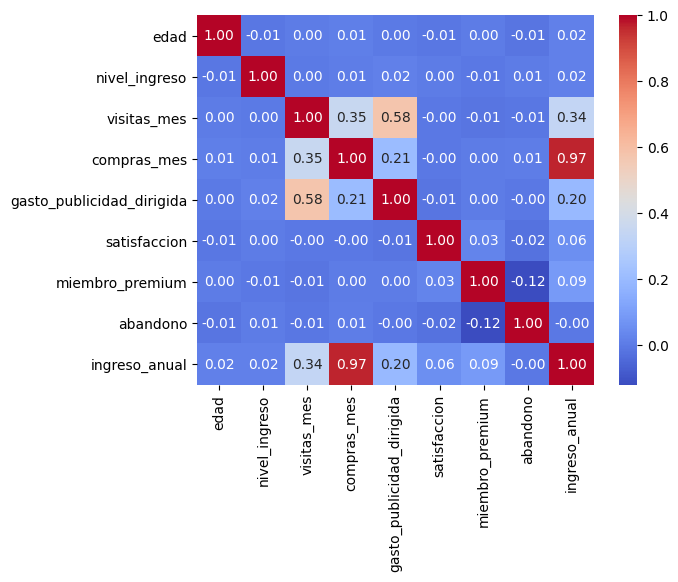

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

**Observaciones generales (Heatmap)**
- Se observa una correlación positiva moderada entre `visitas_mes` y `gasto_publicidad_dirigida` (0.58).
- Existe una correlación positiva entre `visitas_mes` y `compras_mes` (0.35).
- La mayoría de las variables presentan correlaciones cercanas a cero, lo que indica relaciones lineales débiles.
- `edad`, `nivel_ingreso` y `satisfaccion` no muestran relaciones lineales relevantes con las demás variables.

**Observaciones respecto a `ingreso_anual`**  
- Presenta una correlación positiva muy fuerte con `compras_mes` (0.97), lo que indica una relación lineal estrecha.
- Muestra una correlación positiva moderada con `visitas_mes` (0.34).
- Tiene una correlación débil con `gasto_publicidad_dirigida` (0.20).
- No presenta relaciones lineales relevantes con la mayoría de las demás variables.


### Scatterplot general

Con base en los resultados del análisis de correlación, no considero necesario generar un scatterplot general para todas las variables, ya que la matriz de correlación permite identificar que la mayoría de las relaciones lineales son débiles o cercanas a cero.

Sin embargo, recomiendo generar scatterplots específicos para profundizar en las relaciones más relevantes:

- `compras_mes` vs. `ingreso_anual` (0.97): correlación positiva muy fuerte.
- `visitas_mes` vs. `ingreso_anual` (0.34): correlación positiva moderada.
- `gasto_publicidad_dirigida` vs. `ingreso_anual` (0.20): correlación positiva moderada-baja.


<div class="alert alert-block alert-success">

Tu razonamiento para omitir un diagrama de dispersión (scatterplot) general es acertado, ya que la mayoría de los coeficientes están cerca de cero. La lista de pares recomendados ahora coincide con lo que graficas después: compras, visitas y gasto en publicidad, cada uno frente a `ingreso_anual`, junto con sus coeficientes del mapa de calor (heatmap).

</div>

### Scatterplot para pares clave

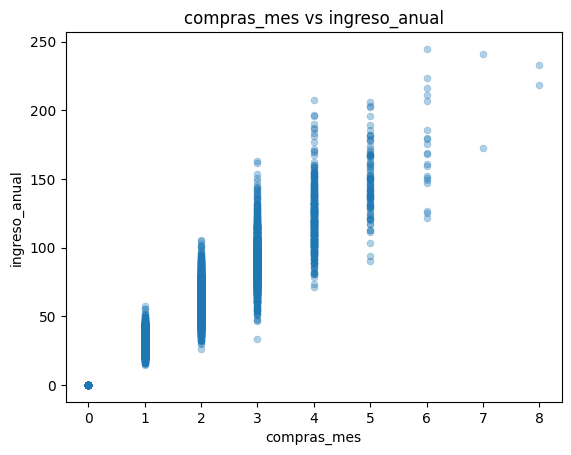

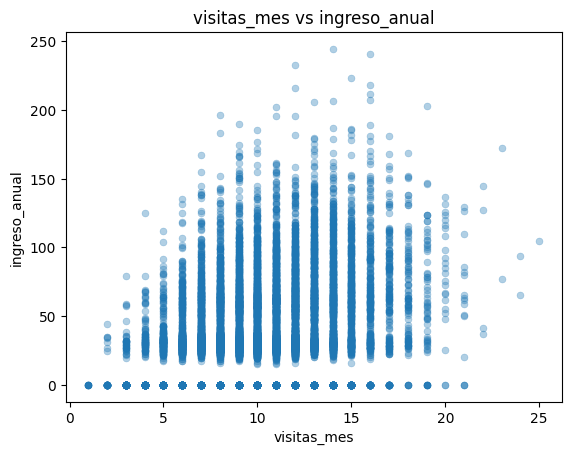

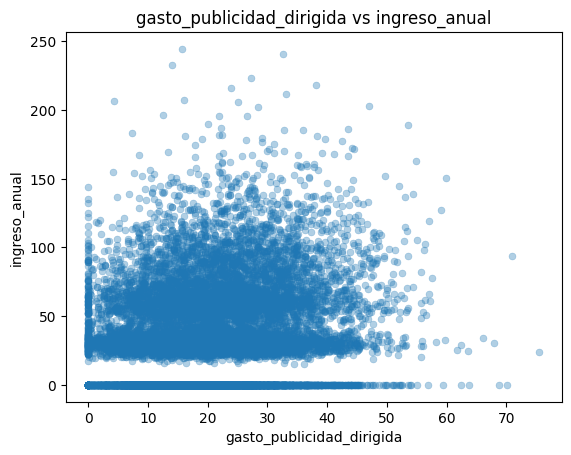

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
pares = [
    ("compras_mes", "ingreso_anual"),
    ("visitas_mes", "ingreso_anual"),
    ("gasto_publicidad_dirigida", "ingreso_anual")
]
for x, y in pares:
    sns.scatterplot(data=df, x=x, y=y, alpha=0.35, s=25, edgecolor=None)  
    plt.title(f"{x} vs {y}")
    plt.show()

**Observaciones iniciales (Scatterplot)**

`compras_mes` **vs** `ingreso_anual`
- **Dirección:** Positiva muy fuerte. A mayor número de compras mensuales, generalmente se observa un mayor ingreso anual.
- **Dispersión:** Relativamente baja dentro de cada nivel de compras, aunque aumenta conforme crece el número de compras.
- **Outliers:** Se observan algunos clientes con ingresos considerablemente superiores al resto, especialmente en los niveles de 6 a 8 compras mensuales.
- **Posible colinealidad:** Alta, consistente con la correlación de 0.97. Conviene investigar si ambas variables comparten información o tienen una relación matemática.

`visitas_mes` **vs** `ingreso_anual`
- **Dirección:** Positiva moderada. En general, un mayor número de visitas se relaciona con mayores ingresos.
- **Dispersión:** Alta. Clientes con una cantidad similar de visitas presentan ingresos muy diferentes.
- **Outliers:** Se identifican algunos clientes con ingresos superiores a 200, incluso con niveles intermedios de visitas.
- **Posible colinealidad:** No se observa una relación visual tan fuerte como la existente entre compras e ingresos. La correlación de Pearson es 0.3371.

`gasto_publicidad_dirigida` **vs** `ingreso_anual`
- **Dirección:** Positiva débil. Se aprecia una ligera tendencia a mayores ingresos conforme aumenta el gasto publicitario.
- **Dispersión:** Muy alta. Existe una amplia variabilidad de ingresos para niveles similares de gasto publicitario.
- **Outliers:** Se observan clientes con ingresos superiores a 200 y gastos publicitarios relativamente elevados, así como observaciones alejadas del conjunto principal.
- **Posible colinealidad:** No se aprecia una relación lineal fuerte entre estas variables (Pearson = 0.1975).

## Sección 4 - Coeficientes de correlación y evidencia numérica


En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.


### Pearson / Spearman

In [18]:
# Calcular correlación entre variables relevantes (Pearson)


for x, y in pares:
    pearson = df[[x,y]].corr(method="pearson").iloc[0,1]
    print(f"\n{x} vs {y}")
    print(f"Pearson: {pearson:.3f}")

    


compras_mes vs ingreso_anual
Pearson: 0.967

visitas_mes vs ingreso_anual
Pearson: 0.337

gasto_publicidad_dirigida vs ingreso_anual
Pearson: 0.197


In [19]:
# Calcular correlación entre variables relevantes (Spearman)

for x, y in pares:
    spearman = df[[x,y]].corr(method="spearman").iloc[0,1]
    print(f"\n{x} vs {y}")
    print(f"Spearman: {spearman:.3f}")



compras_mes vs ingreso_anual
Spearman: 0.967

visitas_mes vs ingreso_anual
Spearman: 0.321

gasto_publicidad_dirigida vs ingreso_anual
Spearman: 0.185


**Observaciones de correlación**

`compras_mes` **vs** `ingreso_anual`
- **
Dirección:** positiva.
- **Magnitud:** Muy fuerte (Pearson: 0.967; Spearman: 0.967).
- **Interpretación:** Ambos métodos muestran una relación prácticamente idéntica, lo que confirma una asociación monotónica y lineal muy marcada.
- **Posible colinealidad:** Alta. Se recomienda investigar si ambas variables comparten información o existe una dependencia matemática entre ellas. 

`visitas_mes` **vs** `ingreso_anual`
- **Dirección:** Positiva.
- **Magnitud:** Débil a moderada (Pearson = 0.337; Spearman = 0.321).
- **Interpretación:** Existe una asociación positiva entre las visitas mensuales y el ingreso anual. Los clientes que visitan más frecuentemente la plataforma tienden a generar mayores ingresos, aunque la relación es relativamente débil y presenta variabilidad. La cercanía entre Pearson y Spearman sugiere que no existen diferencias importantes entre la asociación lineal y la monotónica.
- **Posible colinealidad:** No se puede determinar con esta correlación respecto a la variable objetivo. Se deberá comparar visitas mensuales con otras variables explicativas para evaluar una posible multicolinealidad.

`gasto_publicidad_dirigida` **vs** `ingreso_anual`
- **Dirección:** Positiva.
- **Magnitud:** Débil (Pearson = 0.197; Spearman = 0.185).
- **Interpretación:** Se observa una asociación positiva débil. Aunque un mayor gasto en publicidad dirigida tiende a relacionarse con mayores ingresos, la relación es poco marcada. Esto sugiere que existen otros factores que podrían estar relacionados con las diferencias en el ingreso anual.
- **Posible colinealidad:** No se puede concluir que exista multicolinealidad a partir de esta relación. Es necesario analizar su correlación con las demás variables explicativas.

### Punto-biserial

In [20]:
# Calcular correlación entre variables relevantes

print("Punto-biserial(miembro_premium vs ingreso_anual)\n",pointbiserialr( df["miembro_premium"], df["ingreso_anual"] ))
print("Punto-biserial(abandono vs ingreso_anual)\n", pointbiserialr( df["abandono"], df["ingreso_anual"] ))


Punto-biserial(miembro_premium vs ingreso_anual)
 SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)
Punto-biserial(abandono vs ingreso_anual)
 SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)


**Observaciones Punto-biserial**

1. `Miembro_premium` **vs.** `ingreso_anual`
- **Dirección:** Positiva.
- **Magnitud:** Baja (r = 0.0931).
- **Significancia estadística:** Significativa (p = 3.09 × 10⁻³⁰).

**Interpretación:** Existe una relación positiva débil entre pertenecer al plan Premium y el ingreso anual. Los miembros Premium tienden a presentar ingresos anuales ligeramente mayores que los usuarios que no pertenecen a este plan. La relación es estadísticamente significativa, aunque su magnitud es baja.
Con 15,000 filas incluso efectos diminutos pueden alcanzar valores p muy pequeños, y por eso el resultado de Premium (r ≈ 0.09) es detectable pero de tamaño práctico limitado.

2. `Abandono` **vs.** `ingreso_anual`
- **Dirección:** No hay una dirección detectable.
- **Magnitud:** Prácticamente nula (r = -0.0028).
- **Significancia estadística:** No significativa (p = 0.7295).
  
**Interpretación:** No se observa una relación lineal significativa entre el abandono y el ingreso anual. La correlación es prácticamente cero, por lo que no existe evidencia estadística suficiente para afirmar que el ingreso anual esté relacionado con el abandono de los usuarios.

### V de Cramér

In [16]:
# Función para calcular V de Cramér

def cramers_v(df, col_1, col_2):

    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col_1], df[col_2])

    # Calcular Chi-cuadrado
    chi2, p, dof, expected = chi2_contingency(tabla)

    # Calcular V de Cramér
    n = tabla.sum().sum()
    coef_v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    # Mostrar resultados
    print(f"V de Cramér ({col_1} vs {col_2}): {coef_v:.3f}")
    print(f"Valor p: {p:.6f}")

    return coef_v, p

In [17]:
# Aplicar V de Cramér en variables relevantes

cramers_v(df, "tipo_dispositivo", "region")


V de Cramér (tipo_dispositivo vs region): 0.012
Valor p: 0.596477


(0.012378338407739397, 0.5964767124605646)

Observaciones V de Cramér en `tipo_dispositivo` **vs** `region`
- **Magnitud:** prácticamente nula (0.012). Existe una asociación extremadamente débil entre ambas variables.
- **Significancia estadística:** el valor p es 0.596477, superior a 0.05. No existe evidencia estadística suficiente para rechazar la hipótesis de independencia.
- **Interpretación:** No se observa una asociación relevante entre el tipo de dispositivo utilizado y la región geográfica del usuario. El valor de V de Cramér (0.012) indica que la relación entre ambas variables categóricas es prácticamente inexistente. Además, el valor p superior a 0.05 indica que no existe evidencia estadística suficiente para afirmar que ambas variables estén relacionadas.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Las compras mensuales estan fuertemente asociadas con el ingreso anual

**Evidencia visual:** 
<div align="center">
<img src="attachment:a9133218-9d44-49d7-9962-ac9b46dd550d.png" width="400">
</div>

El scatterplot muestra una tendencia positiva muy marcada entre las compras mensuales y el ingreso anual. Los puntos siguen un patrón lineal relativamente definido, aunque existe cierta dispersión en los niveles más altos de compras.

**Evidencia numérica:** 

Pearson: 0.967  |  Spearman: 0.967

Ambos coeficientes indican una correlación positiva muy fuerte.

**Interpretación**  
Los clientes que realizan más compras mensuales tienden a generar mayores ingresos anuales para NovaRetail+. Esta relación es consistente tanto en términos lineales como monotónicos.

**No podemos afirmar**  
No podemos afirmar que incrementar la cantidad de compras mensuales provoque necesariamente un aumento proporcional del ingreso anual. Tampoco podemos descartar que exista una relación matemática entre ambas variables, por lo que sería conveniente revisar cómo se calcula el ingreso anual.

**Implicación de negocio**  
Conviene priorizar estrategias de retención, recompra y fidelización para incrementar la frecuencia de compra. También resulta importante identificar a los clientes recurrentes y analizar su contribución al ingreso total.

### Hallazgo 2 — Las visitas mensuales se asocian positivamente con el ingreso anual y con el gasto publicitario dirigido

**Evidencia visual:** 

<div align="center">
<img src="attachment:e4539435-5cf8-4dcc-ad63-ff8935394a68.png" width="400">
</div>

Los scatterplots de `visitas_mes` frente a `ingreso_anual` y frente a `gasto_publicidad_dirigida` muestran tendencias positivas, aunque con dispersión.

**Evidencia numérica:** 
`visitas_mes` vs. `ingreso_anual`: Pearson = 0.3371 | Spearman = 0.3210.
`visitas_mes` vs. `gasto_publicidad_dirigida`: Pearson = 0.5789 | Spearman = 0.5593.

**Interpretación**  
Los clientes que visitan con mayor frecuencia tienden a registrar mayor ingreso anual y mayores niveles de gasto publicitario dirigido. La asociación con publicidad es moderada; la asociación con ingreso es moderada-baja.

**No podemos afirmar**  
No podemos afirmar que incrementar las visitas o el gasto publicitario provoque mayores ingresos. Tampoco puede concluirse que el gasto publicitario sea eficiente sin medir conversiones, costos e ingresos atribuibles.

**Implicación de negocio**  
Conviene analizar el embudo visitas → compras → ingreso y evaluar campañas con métricas de conversión, costo de adquisición y retorno de inversión. Deben identificarse también clientes con muchas visitas, pero pocas compras.

## Sección 6 - Limitaciones y próximos pasos


### **Limitaciones**
- **Correlación ≠ causalidad:** Las asociaciones identificadas no permiten determinar relaciones causa-efecto.
- **Distribución del ingreso:** el 30.45% de los clientes presenta `ingreso_anual` igual a cero y la distribución tiene asimetría positiva (≈ 1.04). Esto puede influir en Pearson; Spearman sirve como complemento.
- **Posible dependencia matemática:** La correlación de 0.9671 entre `compras_mes` e `ingreso_anual` requiere revisar la fórmula y el origen de esta última variable.
- **Variables no consideradas:** Pueden existir otros factores que influyan en el comportamiento de compra y abandono de los clientes.
- **Alcance temporal:** el conjunto corresponde a 2024; no permite por sí solo evaluar tendencias de varios años ni anticipar el comportamiento futuro.
- **Significancia y relevancia práctica:** con 15,000 registros, asociaciones pequeñas pueden ser estadísticamente significativas; la magnitud debe guiar la interpretación de negocio.
- **Alcance de la segmentación:** las comparaciones descriptivas por membresía, región y dispositivo no controlan simultáneamente otras variables.

### **Próximos pasos** 


**[Paso 1] — Validar la métrica de ingreso**

- Documentar cómo se calcula `ingreso_anual` y confirmar si se deriva del número de compras.
- Revisar la correlación compras-ingreso después de validar la definición para evitar una conclusión circular o fuga de información.

**[Paso 2] — Analizar la conversión comercial**

- Evaluar la relación entre visitas y compras mediante tasas de conversión.

- Identificar segmentos con muchas visitas, pero pocas compras, para detectar oportunidades de mejora.

**[Paso 3] — Profundizar en retención y membresía**

- Comparar tasas de abandono entre miembros Premium y no Premium.
- En estos datos, la tasa descriptiva de abandono es 16.81% para no Premium y 4.36% para Premium; investigar esta diferencia con análisis adicional, sin atribuir causalidad a la membresía.

**[Paso 4] — Profundizar en retención y membresía**

- Relacionar gasto publicitario con conversiones e ingresos atribuibles.
- Calcular costo de adquisición y retorno de inversión por campaña o segmento.


**[Paso 5] — Construir análisis multivariable**
- Incorporar variables de producto, precio, promociones y antigüedad.
- Validar modelos con datos separados temporalmente y evitar utilizar variables que incorporen directamente el resultado que se intenta predecir.
